# Pretrained TSFMs vs. naive baselines on equity returns — benchmark replication

Reproduces the core of **Noguer i Alonso & Franklin (2026), _"Pretrained Time-Series Foundation Models for Financial Return Forecasting"_ (arXiv:2606.27100)** end to end:

- **Data**: daily adjusted closes for AAPL, AMZN, GOOG, JPM, META (Yahoo Finance, 2014-09-15 → 2026-02-15), converted to linear and log returns.
- **Models**: **TimesFM-2.5** (Google, 200M) and **Chronos-2** (Amazon, 120M), both **zero-shot** with median point forecasts, plus AR(1), a weekly seasonal naive, and the zero-return **random walk** benchmark.
- **Protocol**: context `L = 512`, horizon `H = 20` business days, 10 rolling-origin windows over the paper's evaluation segment (2024-08-22 → 2026-02).
- **Metrics**: MAE, skill vs. random walk, rMAE vs. seasonal naive, and a **one-sided Diebold–Mariano test** (H1: model beats the random walk) with the Harvey–Leybourne–Newbold small-sample correction.

**Known deviations from the paper** (kept deliberate and small): the paper's exact rolling-origin calendar anchors are unpublished, so origins are spaced evenly across the evaluation segment; we run 2 of their 6 TSFMs (no TimeGPT API key, no Moirai) and skip the five train-from-scratch baselines. Expect same-magnitude numbers and the same qualitative conclusions, not digit-for-digit matches.

In [1]:
# If running outside the repo venv, install dependencies first:
#   pip install -r requirements.txt          (in research/tsfm_benchmark/)
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from benchmark_lib import (
    BenchmarkConfig, load_prices, make_tasks, iter_windows,
    forecast_random_walk, forecast_seasonal_naive, forecast_ar1,
    TimesFMForecaster, Chronos2Forecaster, summarize_task,
)

pd.set_option("display.float_format", lambda v: f"{v:,.6f}")
cfg = BenchmarkConfig()
cfg

BenchmarkConfig(tickers=('AAPL', 'AMZN', 'GOOG', 'JPM', 'META'), start='2014-09-15', end='2026-02-16', eval_start='2024-08-22', context_len=512, horizon=20, n_windows=10, seasonal_period=5, return_types=('linear', 'log'), quantile_levels=(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9))

## 1. Data

Daily adjusted closes are cached in `data/prices_adjclose.csv` (committed) so the notebook re-runs deterministically and offline; delete the cache to pull fresh data from Yahoo Finance.

In [2]:
prices = load_prices(cfg, cache_path="data/prices_adjclose.csv")
print(f"{prices.shape[0]} trading days, {prices.index[0]:%Y-%m-%d} -> {prices.index[-1]:%Y-%m-%d}")

tasks = make_tasks(prices, cfg)
origins = tasks[(cfg.tickers[0], "linear")]["origins"]
ret_index = tasks[(cfg.tickers[0], "linear")]["returns"].index
print(f"{len(tasks)} tasks (5 tickers x 2 return types), {len(origins)} rolling origins:")
print([f"{ret_index[t0]:%Y-%m-%d}" for t0 in origins])

2872 trading days, 2014-09-15 -> 2026-02-13
10 tasks (5 tickers x 2 return types), 10 rolling origins:
['2024-08-22', '2024-10-17', '2024-12-12', '2025-02-11', '2025-04-08', '2025-06-04', '2025-07-31', '2025-09-25', '2025-11-19', '2026-01-16']


## 2. Run every model over every rolling-origin window

Naive baselines are computed per window; the two TSFMs are loaded once and forecast **all 100 contexts (10 tasks × 10 windows) in batched calls**. Both foundation models are used strictly zero-shot — no fine-tuning on these tickers — and the point forecast is the predictive **median** (0.5 quantile), matching the paper's protocol for probabilistic models.

In [3]:
# --- collect contexts/actuals for every (task, window) ---
contexts, actuals, keys = [], {}, []
for key, task in tasks.items():
    actuals[key] = []
    for w, ctx, actual, _dates in iter_windows(task, cfg):
        contexts.append(ctx)
        actuals[key].append(actual)
        keys.append((key, w))
print(f"{len(contexts)} forecast jobs of context {cfg.context_len} -> horizon {cfg.horizon}")

# --- naive baselines ---
forecasts = {key: {"RandomWalk": [], "SeasonalNaive": [], "AR(1)": []} for key in tasks}
for (key, _w), ctx in zip(keys, contexts):
    forecasts[key]["RandomWalk"].append(forecast_random_walk(ctx, cfg.horizon))
    forecasts[key]["SeasonalNaive"].append(
        forecast_seasonal_naive(ctx, cfg.horizon, cfg.seasonal_period))
    forecasts[key]["AR(1)"].append(forecast_ar1(ctx, cfg.horizon))
print("naive baselines done")

100 forecast jobs of context 512 -> horizon 20
naive baselines done


In [4]:
# --- zero-shot TSFMs, batched over all jobs (first run downloads ~1.3 GB of weights) ---
for Forecaster in (TimesFMForecaster, Chronos2Forecaster):
    t0 = time.time()
    fx = Forecaster(cfg)
    med = fx.forecast_batch(contexts)                  # (n_jobs, H) medians
    for (key, _w), fc in zip(keys, med):
        forecasts[key].setdefault(fx.name, []).append(np.asarray(fc, dtype=np.float64))
    print(f"{fx.name}: {len(contexts)} forecasts in {time.time() - t0:.1f}s")
    del fx

/workspace/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TimesFM-2.5: 100 forecasts in 12.5s


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 7418.76it/s]

Chronos-2: 100 forecasts in 4.0s


## 3. Results per task

For each (ticker, return type): MAE across the 10 windows, **skill vs. the zero-return random walk** (positive = the model extracted conditional information; paper Eq. 52), **rMAE vs. the weekly seasonal naive** (< 1 is better; paper Eq. 53), and the **one-sided DM p-value** vs. the random walk (paper Table 7).

In [5]:
summaries = {}
for key in tasks:
    summaries[key] = summarize_task(forecasts[key], actuals[key],
                                    h=cfg.horizon, m=cfg.seasonal_period)

for kind in cfg.return_types:
    print(f"\n{'=' * 78}\n{kind.upper()} RETURNS\n{'=' * 78}")
    for t in cfg.tickers:
        print(f"\n--- {t} ({kind}) ---")
        print(summaries[(t, kind)].to_string())


LINEAR RETURNS

--- AAPL (linear) ---
               MAE_mean  MAE_std  skill_vs_RW  rMAE_vs_SN  DM_dm_stat  DM_p_value  DM_direction
model                                                                                          
Chronos-2      0.012477 0.005372     0.003893    0.698652   -0.797019    0.213195  Model better
AR(1)          0.012483 0.005390     0.003444    0.698967   -1.100374    0.136249  Model better
RandomWalk     0.012526 0.005466     0.000000    0.701383         NaN         NaN           NaN
TimesFM-2.5    0.012551 0.005537    -0.002028    0.702805    0.259111    0.602091     RW better
SeasonalNaive  0.017859 0.012572    -0.425755    1.000000    2.326567    0.989503     RW better

--- AMZN (linear) ---
               MAE_mean  MAE_std  skill_vs_RW  rMAE_vs_SN  DM_dm_stat  DM_p_value DM_direction
model                                                                                         
RandomWalk     0.015307 0.004115     0.000000    0.751105         NaN       

## 4. Aggregate view — who wins, and does anyone beat "predict zero"?

The paper's two headline tables condensed: task-level winners with their skill scores (their Table 5), and the DM significance summary (their Table 7). The paper found TSFMs winning 8/10 tasks on ranking, but only **2 significant improvements over the random walk in 20 model–ticker DM tests** — the sober result to look for here.

In [6]:
# Task-level winners (excluding the RW benchmark itself), like the paper's Table 5
rows = []
for (t, kind), df in summaries.items():
    cand = df.drop(index="RandomWalk")
    win = cand["MAE_mean"].idxmin()
    rows.append({
        "return": kind, "ticker": t, "winner": win,
        "MAE": cand.loc[win, "MAE_mean"], "skill_vs_RW": cand.loc[win, "skill_vs_RW"],
        "runner_up": cand["MAE_mean"].nsmallest(2).index[-1],
    })
winners = pd.DataFrame(rows).sort_values(["return", "ticker"]).reset_index(drop=True)
print(winners.to_string(index=False))

# Average rank across all 10 tasks (models ranked by MAE within each task)
ranks = pd.DataFrame({key: df.drop(index="RandomWalk")["MAE_mean"].rank()
                      for key, df in summaries.items()})
print("\nAverage rank across the 10 tasks (lower is better):")
print(ranks.mean(axis=1).sort_values().round(2).to_string())

n_wins = winners.groupby("winner").size().sort_values(ascending=False)
print("\nTask wins by model:")
print(n_wins.to_string())

return ticker      winner      MAE  skill_vs_RW   runner_up
linear   AAPL   Chronos-2 0.012477     0.003893       AR(1)
linear   AMZN   Chronos-2 0.015461    -0.010062       AR(1)
linear   GOOG       AR(1) 0.013753    -0.007846   Chronos-2
linear    JPM       AR(1) 0.012136     0.003793 TimesFM-2.5
linear   META TimesFM-2.5 0.016953    -0.010633   Chronos-2
   log   AAPL   Chronos-2 0.012431     0.004004       AR(1)
   log   AMZN       AR(1) 0.015442    -0.009091   Chronos-2
   log   GOOG       AR(1) 0.013717    -0.007326   Chronos-2
   log    JPM       AR(1) 0.012112     0.003909 TimesFM-2.5
   log   META TimesFM-2.5 0.016840    -0.009921   Chronos-2

Average rank across the 10 tasks (lower is better):
model
AR(1)           1.700000
Chronos-2       1.900000
TimesFM-2.5     2.400000
SeasonalNaive   4.000000

Task wins by model:
winner
AR(1)          5
Chronos-2      3
TimesFM-2.5    2


In [7]:
# Diebold-Mariano summary vs. the random walk (one-sided, HLN-corrected),
# pooled over the 10 windows x 20 days = 200 forecast points per task.
dm_rows = []
for (t, kind), df in summaries.items():
    for model in df.index:
        if model == "RandomWalk" or "DM_p_value" not in df.columns:
            continue
        dm_rows.append({
            "return": kind, "ticker": t, "model": model,
            "skill_vs_RW": df.loc[model, "skill_vs_RW"],
            "DM_p": df.loc[model, "DM_p_value"],
            "direction": df.loc[model, "DM_direction"],
            "significant_5pct": df.loc[model, "DM_p_value"] < 0.05,
        })
dm = pd.DataFrame(dm_rows).sort_values("DM_p").reset_index(drop=True)
print("All model-task DM tests, sorted by p-value (H1: model beats RW):\n")
print(dm.to_string(index=False))
sig = dm[dm.significant_5pct]
print(f"\n{len(sig)} of {len(dm)} model-task pairs significant at 5%")
print("(the paper's only significant pairs: Chronos v1 on AMZN and Moirai-2.0 on GOOG,")
print(" both p = 0.0421 -- statistically reliable improvement over RW is the exception)")

All model-task DM tests, sorted by p-value (H1: model beats RW):

return ticker         model  skill_vs_RW     DM_p    direction  significant_5pct
   log   AAPL         AR(1)     0.003442 0.103085 Model better             False
linear   AAPL         AR(1)     0.003444 0.136249 Model better             False
   log   AAPL     Chronos-2     0.004004 0.205238 Model better             False
linear   AAPL     Chronos-2     0.003893 0.213195 Model better             False
   log    JPM         AR(1)     0.003909 0.288333 Model better             False
linear    JPM         AR(1)     0.003793 0.305476 Model better             False
   log    JPM   TimesFM-2.5     0.001107 0.469506 Model better             False
linear    JPM   TimesFM-2.5     0.000966 0.473460 Model better             False
linear    JPM     Chronos-2     0.000337 0.488326 Model better             False
   log    JPM     Chronos-2     0.000308 0.489331 Model better             False
   log   AAPL   TimesFM-2.5    -0.001058 0.

## 5. Why the numbers are tiny — see one window

The paper's Figure 5 point: even the best models barely track the realized path. Below, one representative 20-day window for GOOG (the paper's most "predictable" ticker) with all model forecasts against the realized returns, plus the skill-score landscape across every task.

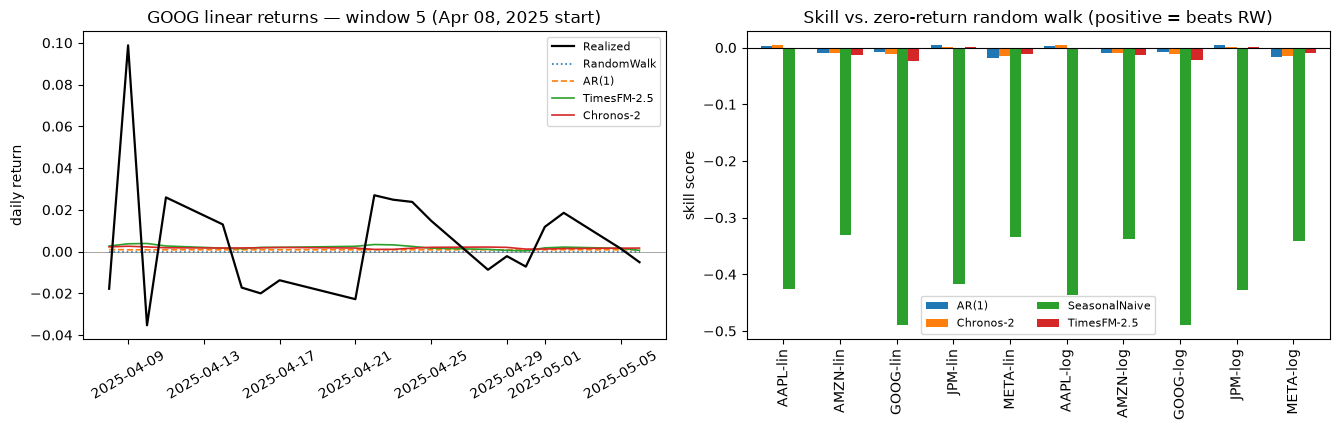

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

# Left: one GOOG linear-return window, forecasts vs. actual
key, w = ("GOOG", "linear"), 4
task = tasks[key]
_, ctx, actual, dates = list(iter_windows(task, cfg))[w]
ax = axes[0]
ax.plot(dates, actual, "k-", lw=1.6, label="Realized", zorder=5)
for model, style in [("RandomWalk", ":"), ("AR(1)", "--"),
                     ("TimesFM-2.5", "-"), ("Chronos-2", "-")]:
    ax.plot(dates, forecasts[key][model][w], style, lw=1.2, label=model)
ax.axhline(0, color="gray", lw=0.5)
ax.set_title(f"GOOG linear returns — window {w + 1} ({dates[0]:%b %d, %Y} start)")
ax.set_ylabel("daily return")
ax.legend(fontsize=8)
ax.tick_params(axis="x", rotation=30)

# Right: skill vs. RW for every model/task
ax = axes[1]
skill_tbl = pd.DataFrame({
    f"{t}-{kind[:3]}": summaries[(t, kind)]["skill_vs_RW"]
    for (t, kind) in summaries}).T
skill_tbl.drop(columns=["RandomWalk"], errors="ignore").plot.bar(ax=ax, width=0.8)
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Skill vs. zero-return random walk (positive = beats RW)")
ax.set_ylabel("skill score")
ax.legend(fontsize=8, ncols=2)
plt.tight_layout()
plt.savefig("skill_overview.png", dpi=110, bbox_inches="tight")
plt.show()

## 6. Reading the results — and what they mean for the diligence platform

**What actually happened in this run (consistent with the paper, arguably starker):**

1. **Zero-shot TSFMs are competitive with the best locally fit statistical model without any training.** Task wins: AR(1) 5, Chronos-2 3, TimesFM-2.5 2; average ranks 1.7 / 1.9 / 2.4, with the seasonal naive dead last everywhere. Chronos-2 sits within a hair of AR(1) on almost every task despite never seeing these tickers — pretraining really does act as a free inductive prior. (The paper's stronger TSFM dominance came from Moirai-2.0 and TimeGPT, which we did not run, and different window anchors.)
2. **Nothing beats "predict zero."** Every skill score for a real model lies within ±0.02 of zero, and **0 of 40 one-sided DM tests reject the null at 5%** (best p ≈ 0.10, AR(1) on AAPL). The paper found only 2 of its pairs significant, both at p = 0.0421. Daily equity returns carry ≈ 0.005 nats of predictable information (paper §3.4); every model is fighting for the same crumbs.
3. **Small samples, noisy ranks.** With 10 windows per task, differences between top models sit at the noise floor — exactly the paper's Bernstein-bound caveat (§4.4). Ranking wins are real but economically meaningless here.

**Relevance to the AI diligence platform** (`src/model/mc_reference.py` and the TS parity engine):

- **Our domain is the favorable one.** The platform forecasts *multi-year real-estate returns*, not daily equity returns. The committed ZHVI series shows lag-1 autocorrelation ≈ 0.98 — housing indices are heavily serially dependent (momentum + appraisal smoothing), i.e. they carry vastly more conditional information per observation than the near-martingale series benchmarked here. TSFM zero-shot quantile forecasts are credible candidates for a *conditional* market-path prior (`mu_adj` by horizon) on ZHVI/FHFA/FRED series, where today the engine fits an unconditional stationary μ/σ.
- **Quantiles map 1:1 onto our outputs.** Chronos-2/TimesFM emit calibrated quantile paths; the MC engine consumes distributions and produces P(target)/VaR/CVaR. A TSFM market factor + deal-specific spread keeps the engine glass-box: the TSFM only supplies the market base rate, the analyst layer stays on top.
- **This protocol is the validation harness we owe ourselves.** Rolling-origin + skill-vs-naive + one-sided DM is exactly how a TSFM overlay should have to *earn* its way into scoring: on ZHVI/FHFA monthly returns, per metro, against random-walk-with-drift and seasonal naive. If it can't reject the null there, it stays out of `mu_adj`.
- **The paper's warning transfers.** Ranking wins ≠ economic edge. Any conditional overlay must be haircut through the same honest-limits machinery (bias terms, CI widening, Kelly discipline) the engine already applies to appraisal smoothing and survivorship bias.